# Лабораторная работа 3. Кластеризация

## Введение

### Цель работы
Изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

### Постановка задачи

1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.

## Описание датасета

Используется набор данных seed.csv. Он содержит измерения характеристик зерен трех разновидностей пшеницы: Kama, Rosa и Canadian. В исходном наборе 210 наблюдений: по 70 наблюдений каждого вида. Для каждого зерна записаны семь непрерывных числовых характеристик и одна исходная метка разновидности.

1. AREA - площадь зерна, числовой признак
2. PERIMETER - периметр зерна, числовой признак
3. COMPACTNESS - компактность зерна (в исходном наборе рассчитывается как 4π·AREA/PERIMETER²), числовой признак
4. LENGTH - длина зерна, числовой признак
5. WIDTH - ширина зерна, числовой признак
6. ASSYMMETRY_COEFFICIENT - коэффициент асимметрии, числовой признак
7. GROOVE_LENGTH - длина бороздки зерна, числовой признак
8. TYPE - исходная разновидность: 1 - Kama, 2 - Rosa, 3 - Canadian; только внешняя проверка, в кластеризацию не включается

### Импорт библиотек

In [76]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import shapiro, skew
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, cdist
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, adjusted_mutual_info_score,
    normalized_mutual_info_score, rand_score, fowlkes_mallows_score
)
from sklearn.decomposition import PCA
from IPython.display import display

### Загрузка датасета

In [77]:
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

DATA_PATH = Path('seed.csv')

df = pd.read_csv(DATA_PATH)
EXPECTED_COLUMNS = [
    'AREA', 'PERIMETER', 'COMPACTNESS', 'LENGTH', 'WIDTH',
    'ASSYMMETRY_COEFFICIENT', 'GROOVE_LENGTH', 'TYPE'
]

FEATURES = EXPECTED_COLUMNS[:-1]
TARGET = 'TYPE'
CLASS_NAMES = {1: 'Kama', 2: 'Rosa', 3: 'Canadian'}
X = df[FEATURES].copy()       
y_reference = df[TARGET].astype(int).copy()  #

print('Первые пять строк датасета:')
display(df.head())
print(f'Размерность датасета: {df.shape[0]} строк × {df.shape[1]} столбцов')
print(f'Число объектов: {len(df)}')
print(f'Число числовых признаков для кластеризации: {len(FEATURES)}')
print(f'Наличие пропусков: {df.isna().sum().sum()}')
print(f'Количество полностью повторяющихся строк: {df.duplicated().sum()}')
print('\nТипы данных:')
display(df.dtypes.rename('Тип данных').to_frame())
print('\nЧисло объектов каждого исходного типа:')
class_counts = y_reference.map(CLASS_NAMES).value_counts().reindex(['Kama', 'Rosa', 'Canadian'])
display(class_counts.rename('Количество объектов').to_frame())

Первые пять строк датасета:


,AREA,PERIMETER,COMPACTNESS,LENGTH,WIDTH,ASSYMMETRY_COEFFICIENT,GROOVE_LENGTH,TYPE
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


Размерность датасета: 210 строк × 8 столбцов
Число объектов: 210
Число числовых признаков для кластеризации: 7
Наличие пропусков: 0
Количество полностью повторяющихся строк: 0

Типы данных:


,Тип данных
AREA,float64
PERIMETER,float64
COMPACTNESS,float64
LENGTH,float64
WIDTH,float64
ASSYMMETRY_COEFFICIENT,float64
GROOVE_LENGTH,float64
TYPE,int64



Число объектов каждого исходного типа:


,Количество объектов
TYPE,
Kama,70
Rosa,70
Canadian,70


По результатам загрузки в датасете 210 строк и 8 столбцов: семь признаков имеют числовой тип, TYPE - целочисленная категория. Пропущенных значений и полностью повторяющихся строк нет. В каждой из трех исходных категорий находится по 70 зерен, то есть классы сбалансированы.

### Дескрептивный анализ

In [78]:
summary = X.describe().T
summary['Медиана'] = X.median()
summary['Асимметрия распределения'] = X.apply(skew)
summary = summary[['count', 'mean', 'Медиана', 'std', 'min', '25%', '50%', '75%', 'max', 'Асимметрия распределения']]
summary = summary.rename(columns={
    'count': 'Количество', 'mean': 'Среднее', 'std': 'Станд. отклонение',
    'min': 'Минимум', '25%': 'Q1', '50%': 'Медиана (Q2)', '75%': 'Q3', 'max': 'Максимум'
})
display(summary.round(4))

print('Диапазоны значений признаков:')
ranges = pd.DataFrame({'Минимум': X.min(), 'Максимум': X.max(), 'Размах': X.max() - X.min()})
display(ranges.round(4))

,Количество,Среднее,Медиана,Станд. отклонение,Минимум,Q1,Медиана (Q2),Q3,Максимум,Асимметрия распределения
AREA,210.0,14.8475,14.3550,2.9097,10.5900,12.2700,14.3550,17.3050,21.1800,0.3970
PERIMETER,210.0,14.5593,14.3200,1.3060,12.4100,13.4500,14.3200,15.7150,17.2500,0.3838
COMPACTNESS,210.0,0.8710,0.8734,0.0236,0.8081,0.8569,0.8734,0.8878,0.9183,-0.5341
LENGTH,210.0,5.6285,5.5235,0.4431,4.8990,5.2622,5.5235,5.9798,6.6750,0.5217
WIDTH,210.0,3.2586,3.2370,0.3777,2.6300,2.9440,3.2370,3.5618,4.0330,0.1334
ASSYMMETRY_COEFFICIENT,210.0,3.7002,3.5990,1.5036,0.7651,2.5615,3.5990,4.7688,8.4560,0.3988
GROOVE_LENGTH,210.0,5.4081,5.2230,0.4915,4.5190,5.0450,5.2230,5.8770,6.5500,0.5579


Диапазоны значений признаков:


,Минимум,Максимум,Размах
AREA,10.5900,21.1800,10.5900
PERIMETER,12.4100,17.2500,4.8400
COMPACTNESS,0.8081,0.9183,0.1102
LENGTH,4.8990,6.6750,1.7760
WIDTH,2.6300,4.0330,1.4030
ASSYMMETRY_COEFFICIENT,0.7651,8.4560,7.6909
GROOVE_LENGTH,4.5190,6.5500,2.0310


По описательной статистике видно, что средние значения и медианы признаков близки друг к другу (например, AREA: 14,85 и 14,36; PERIMETER: 14,56 и 14,32; WIDTH: 3,26 и 3,24), поэтому сильных смещений центра распределений нет. Коэффициент асимметрии по модулю не превышает 0,56: умеренная правосторонняя асимметрия у GROOVE_LENGTH (0,56), LENGTH (0,52), AREA (0,40), ASSYMMETRY_COEFFICIENT (0,40) и PERIMETER (0,38), почти симметричен WIDTH (0,13), а COMPACTNESS слегка скошен влево (-0,53).

Шкалы признаков сильно различаются. Размах AREA равен 10,59, ASSYMMETRY_COEFFICIENT - 7,69, а у COMPACTNESS всего 0,11; стандартное отклонение AREA составляет 2,91, а COMPACTNESS - 0,024. Относительный разброс (стандартное отклонение / среднее) тоже неодинаков: около 40,6% у ASSYMMETRY_COEFFICIENT, около 19,6% у AREA и лишь около 2,7% у COMPACTNESS. Поэтому без масштабирования признаки с большим числовым размахом полностью определяли бы евклидово расстояние, что подтверждает необходимость стандартизации перед кластеризацией.

### Распределение признаков

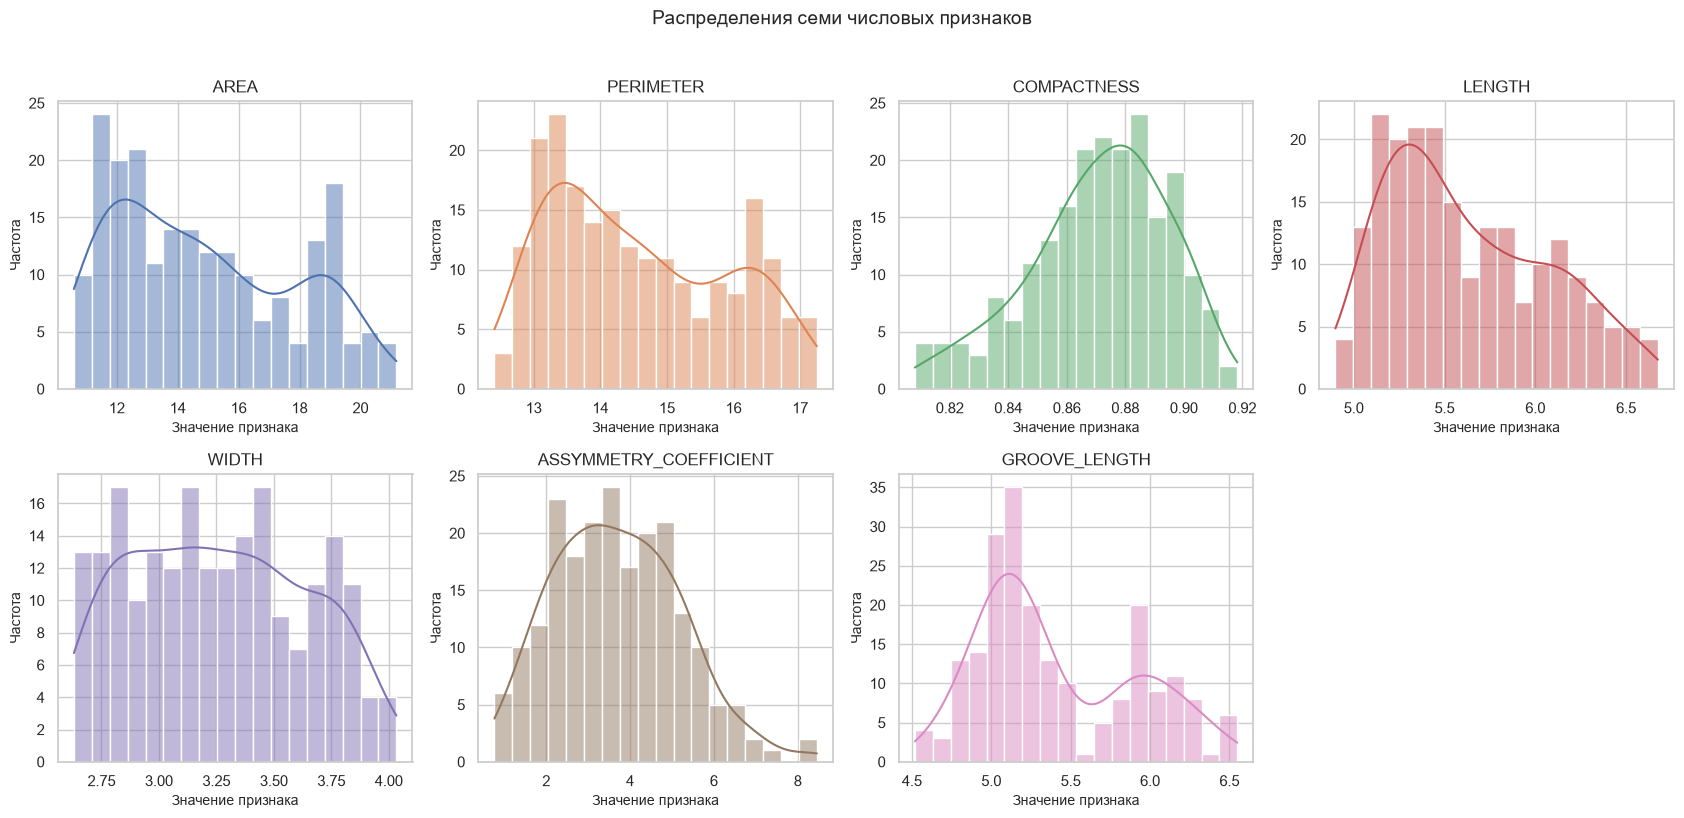

In [79]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
axes = axes.ravel()
for i, feature in enumerate(FEATURES):
    sns.histplot(X[feature], kde=True, bins=18, ax=axes[i], color=sns.color_palette()[i])
    axes[i].set_title(feature)
    axes[i].set_xlabel('Значение признака')
    axes[i].set_ylabel('Частота')
axes[-1].axis('off')
fig.suptitle('Распределения семи числовых признаков', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


По гистограммам видно, что форму, близкую к колоколообразной, имеют только COMPACTNESS (небольшой левый хвост) и ASSYMMETRY_COEFFICIENT (небольшой правый хвост). Распределения AREA, PERIMETER, LENGTH и GROOVE_LENGTH скошены вправо и имеют несколько вершин, что соответствует мелким, средним и крупным зернам; у GROOVE_LENGTH хорошо видны две области значений: около 5 и около 6. Распределение WIDTH почти равномерное (плоская вершина). Для задачи кластеризации это не недостаток: метод K-means и метод Ward не требуют нормальности распределения признаков (в отличие от EM-алгоритма с гауссовыми компонентами), а многовершинность распределений косвенно указывает на наличие внутренних групп в данных.

###  Диаграммы размаха

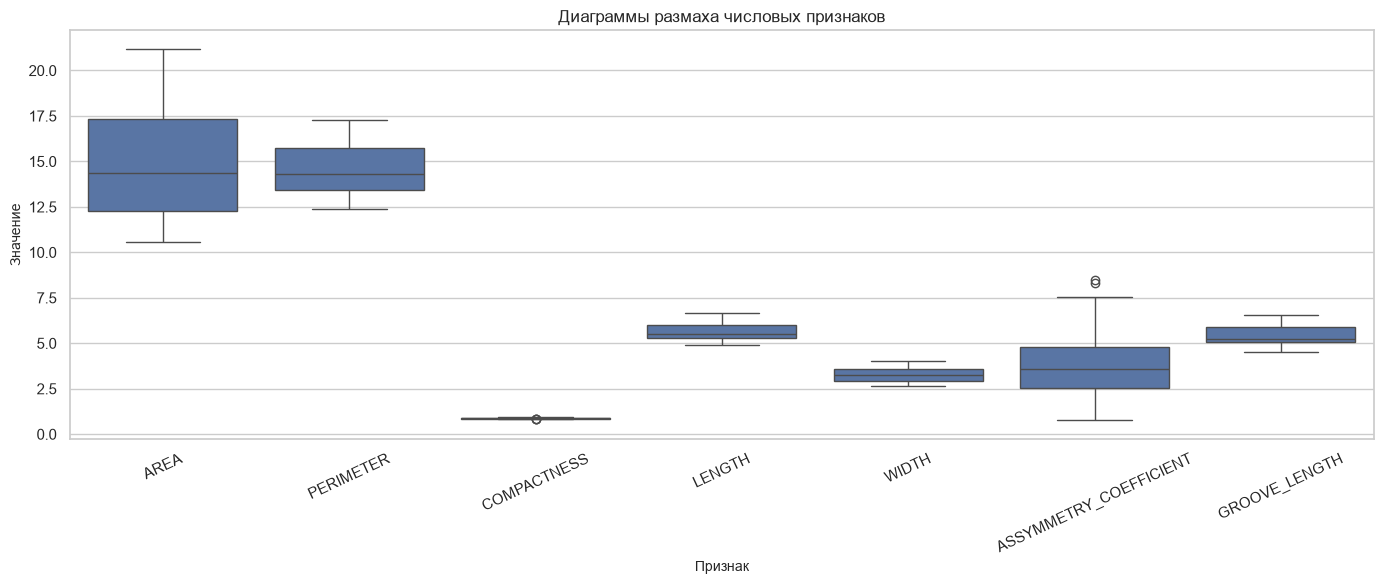

Потенциальные выбросы по каждому признаку (правило 1,5 × IQR):


,Признак,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Потенциальных выбросов
0,AREA,12.27000,17.30500,5.03500,4.71750,24.85750,0
1,PERIMETER,13.45000,15.71500,2.26500,10.05250,19.11250,0
2,COMPACTNESS,0.85690,0.88778,0.03087,0.81059,0.93409,3
3,LENGTH,5.26225,5.97975,0.71750,4.18600,7.05600,0
4,WIDTH,2.94400,3.56175,0.61775,2.01738,4.48837,0
5,ASSYMMETRY_COEFFICIENT,2.56150,4.76875,2.20725,-0.74937,8.07962,2
6,GROOVE_LENGTH,5.04500,5.87700,0.83200,3.79700,7.12500,0


Количество уникальных строк, в которых отмечен хотя бы один потенциальный выброс: 5 из 210
Номера отмеченных наблюдений (нумерация с 1): [158, 159, 175, 204, 208]


,AREA,PERIMETER,COMPACTNESS,LENGTH,WIDTH,ASSYMMETRY_COEFFICIENT,GROOVE_LENGTH,TYPE
157,12.13,13.73,0.8081,5.394,2.745,4.825,5.220,3
158,11.75,13.52,0.8082,5.444,2.678,4.378,5.310,3
174,10.83,12.96,0.8099,5.278,2.641,5.182,5.185,3
203,12.70,13.41,0.8874,5.183,3.091,8.456,5.000,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3


In [80]:
fig, ax = plt.subplots(figsize=(14, 6))
long_X = X.melt(var_name='Признак', value_name='Значение')
sns.boxplot(data=long_X, x='Признак', y='Значение', ax=ax)
ax.set_title('Диаграммы размаха числовых признаков')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

outlier_rows = []
outlier_masks = []
for feature in FEATURES:
    q1 = X[feature].quantile(0.25)
    q3 = X[feature].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (X[feature] < lower) | (X[feature] > upper)
    outlier_masks.append(mask)
    outlier_rows.append({
        'Признак': feature,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Нижняя граница': lower,
        'Верхняя граница': upper,
        'Потенциальных выбросов': int(mask.sum())
    })
outlier_df = pd.DataFrame(outlier_rows)
row_outlier_mask = pd.concat(outlier_masks, axis=1).any(axis=1)
print('Потенциальные выбросы по каждому признаку (правило 1,5 × IQR):')
display(outlier_df.round(5))
print(f'Количество уникальных строк, в которых отмечен хотя бы один потенциальный выброс: {row_outlier_mask.sum()} из {len(df)}')
if row_outlier_mask.any():
    print('Номера отмеченных наблюдений (нумерация с 1):', (np.where(row_outlier_mask)[0] + 1).tolist())
    display(df.loc[row_outlier_mask, FEATURES + [TARGET]].round(4))

По правилу 1,5 × IQR выбросы найдены только в двух признаках: COMPACTNESS (3 значения ниже нижней границы 0,8106: 0,8081; 0,8082 и 0,8099) и ASSYMMETRY_COEFFICIENT (2 значения выше верхней границы 8,08: 8,456 и 8,315). В остальных пяти признаках выбросов нет. Всего отмечено 5 наблюдений из 210 (2,4%): № 158, 159, 175, 204 и 208, и все они относятся к одной исходной разновидности (Canadian).

Выбросы слабые: значения компактности выходят за границу всего на 0,0007-0,0025, а максимальное отклонение от среднего составляет около 3,2σ (ASSYMMETRY_COEFFICIENT = 8,456). Грубых значений, которые можно было бы считать ошибками измерения, нет, значения правдоподобны и отражают естественную изменчивость формы зерен. Поэтому наблюдения оставлены в выборке: их доля мала, а удаление искусственно сузило бы реальный разброс данных. Влияние таких точек на центры кластеров K-means незначительно (5 из 210 объектов, все в пределах 3,2σ).

### Информационная значимость признаков

Для дополнительной того, насколько отдельные характеристики различаются между известными разновидностями, используется однофакторный ANOVA F-критерий. Чем выше F-статистика, тем больше межгрупповая вариация признака по отношению к внутригрупповой. Малое p-value указывает на статистически значимые различия средних значений между категориями.

,Признак,F-критерий,p-value,"Значимость при α=0,05"
0,AREA,548.186479,0.0,Статистически значимые различия
1,PERIMETER,541.579497,0.0,Статистически значимые различия
2,WIDTH,406.302031,0.0,Статистически значимые различия
3,GROOVE_LENGTH,368.950045,0.0,Статистически значимые различия
4,LENGTH,322.185934,0.0,Статистически значимые различия
5,COMPACTNESS,75.869048,0.0,Статистически значимые различия
6,ASSYMMETRY_COEFFICIENT,51.888109,0.0,Статистически значимые различия


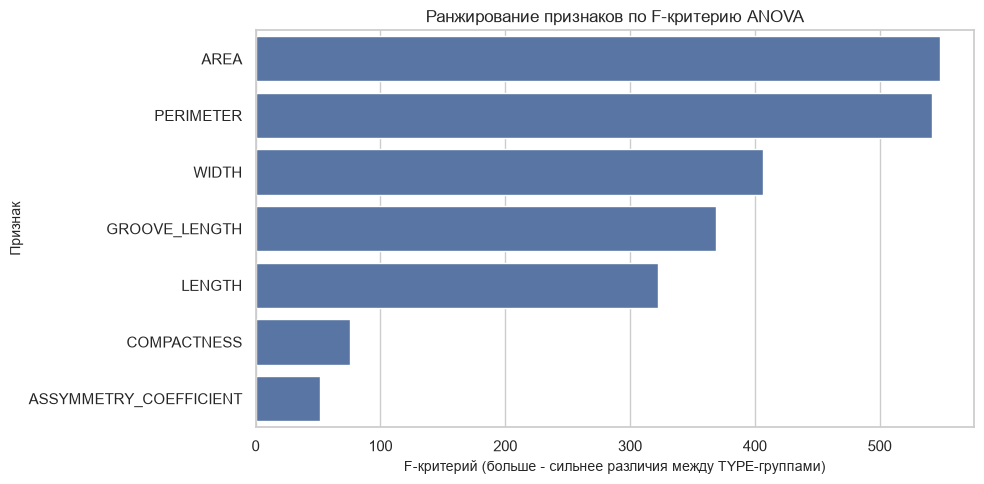

In [81]:
f_values, p_values = f_classif(X, y_reference)
feature_significance = pd.DataFrame({
    'Признак': FEATURES,
    'F-критерий': f_values,
    'p-value': p_values
}).sort_values('F-критерий', ascending=False).reset_index(drop=True)
feature_significance['Значимость при α=0,05'] = np.where(
    feature_significance['p-value'] < 0.05, 'Статистически значимые различия', 'Не выявлены значимые различия'
)
display(feature_significance.round(6))

plt.figure(figsize=(10, 5))
sns.barplot(data=feature_significance, x='F-критерий', y='Признак', color=sns.color_palette()[0])
plt.title('Ранжирование признаков по F-критерию ANOVA')
plt.xlabel('F-критерий (больше - сильнее различия между TYPE-группами)')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

Наибольшие значения F-критерия получены для AREA (примерно 548,19) и PERIMETER (примерно 541,58). Далее следуют WIDTH (около 406,30), GROOVE_LENGTH (около 368,95) и LENGTH (около 322,19). Самые низкие F-значения у COMPACTNESS (около 75,87) и ASSYMMETRY_COEFFICIENT (около 51,89), однако и для них различия между исходными разновидностями статистически значимы (p-value < 0,05). Следовательно, все семь измерений содержат информацию о различиях групп, но площадь и периметр дают наиболее выраженное разделение по исходным типам.

## Предобработка данных

### Стандартизация

Для всех семи числовых признаков применяется **стандартизация `StandardScaler`**. Преобразование выполняется по формуле

$$
z = \frac{x - \mu}{\sigma},
$$
где $x$ - исходное значение признака, $\mu$ - среднее, $\sigma$ - стандартное отклонение обучающей выборки. После преобразования каждый признак имеет среднее, близкое к 0, и стандартное отклонение, близкое к 1.

Выбор обоснован различием шкал: например, AREA измеряется значениями порядка десятков, COMPACTNESS - долями единицы, а ASSYMMETRY_COEFFICIENT имеет собственный диапазон. K-means и Ward используют евклидовы расстояния и чувствительны к масштабу, поэтому без стандартизации признаки с большим числовым размахом могли бы доминировать. 

In [82]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=FEATURES, index=X.index)

print('\nПервые пять стандартизированных наблюдений:')
display(X_scaled_df.head().round(3))


Первые пять стандартизированных наблюдений:


,AREA,PERIMETER,COMPACTNESS,LENGTH,WIDTH,ASSYMMETRY_COEFFICIENT,GROOVE_LENGTH
0,0.142,0.215,0.000,0.304,0.142,-0.986,-0.384
1,0.011,0.008,0.429,-0.169,0.197,-1.788,-0.922
2,-0.192,-0.360,1.442,-0.764,0.208,-0.667,-1.189
3,-0.347,-0.475,1.039,-0.689,0.320,-0.961,-1.230
4,0.445,0.331,1.375,0.067,0.805,-1.563,-0.475


### Матрица диаграмма рассвеивания

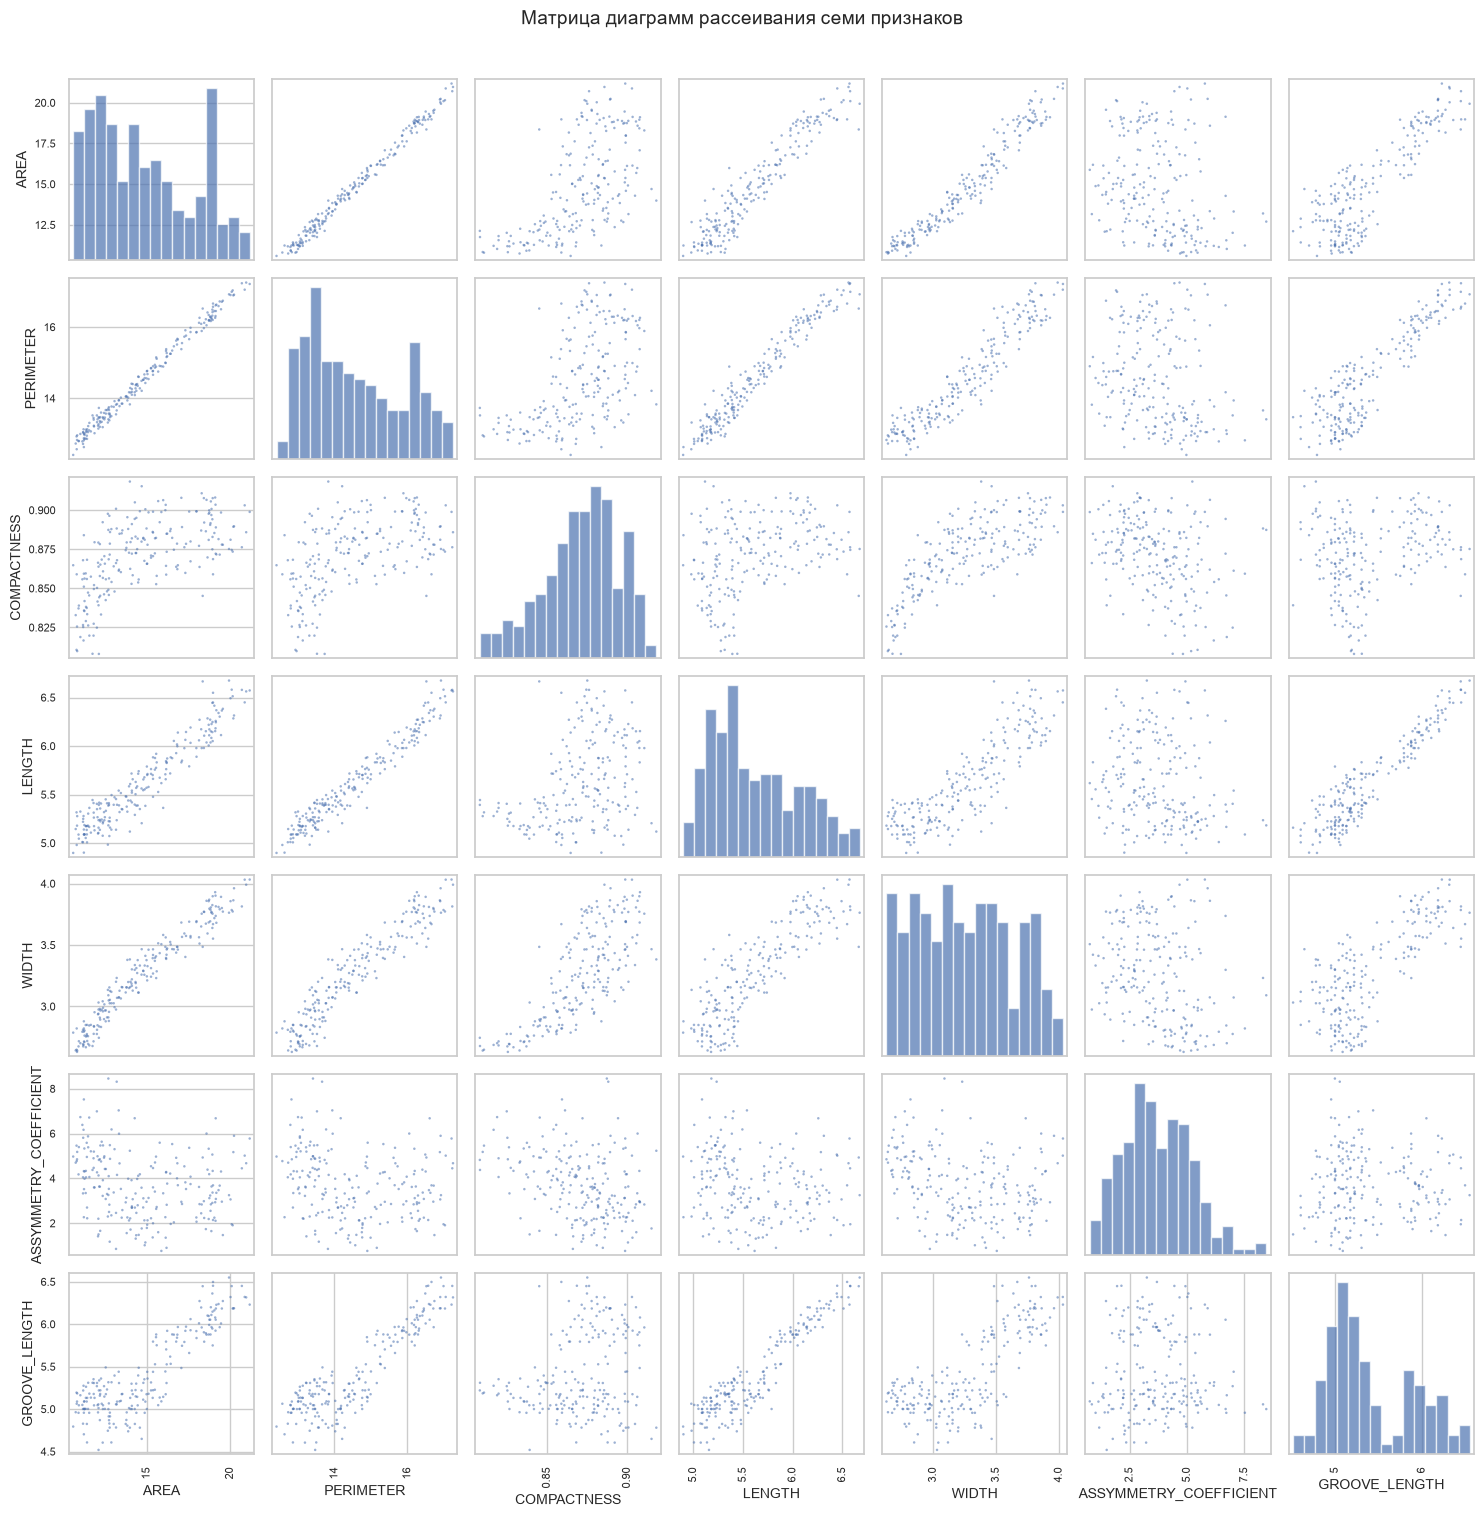

In [83]:
axes = pd.plotting.scatter_matrix(
    X, figsize=(15, 15), diagonal='hist', alpha=0.55, s=13,
    color=sns.color_palette()[0], hist_kwds={'bins': 16, 'alpha': 0.7}
)
plt.suptitle('Матрица диаграмм рассеивания семи признаков', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

- Размерные признаки AREA, PERIMETER, LENGTH и WIDTH связаны почти линейно: точки лежат узкой диагональной полосой, то есть облако данных вытянуто вдоль одного направления.
- Диаграммы с участием COMPACTNESS и ASSYMMETRY_COEFFICIENT дают более рассеянное облако без выраженной линейной связи; именно эти признаки позволяют различать зерна, близкие по размеру.
- Резких пустых промежутков между группами нет: переходы между ними постепенные, группы частично перекрываются, особенно в средней части диапазона размеров.

Предположительно в данных три кластера - мелкие, средние и крупные зерна. Кластеры имеют компактную, близкую к эллипсоидной форму; ничто не указывает на сильно различающиеся по размеру группы или на области с резко отличающейся плотностью; зон шума нет. Такая структура подходит для K-means и метода Ward, а для DBSCAN выраженных разрывов плотности нет.

## Ход работы

### Обоснование выбора метода кластеризации

1. K-means (метод K-средних). Алгоритм распределяет объекты по k кластерам так, чтобы минимизировать сумму квадратов расстояний от объектов до центров назначенных кластеров. Он эффективен для компактных, приблизительно выпуклых групп. Для уменьшения влияния случайного выбора начальных центров используется n_init=10, фиксируется random_state=42.

2. Иерархическая агломеративная кластеризация Ward. Сначала каждый объект является отдельным кластером, затем на каждом шаге объединяются две группы, объединение которых минимально увеличивает внутрикластерную сумму квадратов. Метод Ward также ориентирован на компактные группы и дает дендрограмму, которая помогает оценить структуру последовательных объединений.

Оба алгоритма уместны для сравнения, поскольку матрица рассеивания указывает на группы с приблизительно компактной структурой, а не на явно вытянутые нелинейные или плотностные области произвольной формы. DBSCAN в качестве второго метода здесь не выбран: его результат сильно зависит от eps и min_samples, а выраженной неоднородности плотности или большого количества шума на предварительных графиках не видно.

### Подбор количества кластеров: метод локтя и силуэтный анализ


,k,Инерция,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI к TYPE (только внешняя проверка)
0,2,659.1718,0.4658,255.8548,0.7969,0.4805
1,3,430.6590,0.4007,249.7842,0.9279,0.7733
2,4,371.3017,0.3276,203.1877,1.0626,0.6624
3,5,326.5137,0.2849,179.4830,1.1825,0.5211
4,6,289.8040,0.2798,166.1536,1.1457,0.4719
5,7,262.9736,0.2709,155.2921,1.1864,0.3805
6,8,240.6426,0.2510,147.4209,1.2497,0.3192


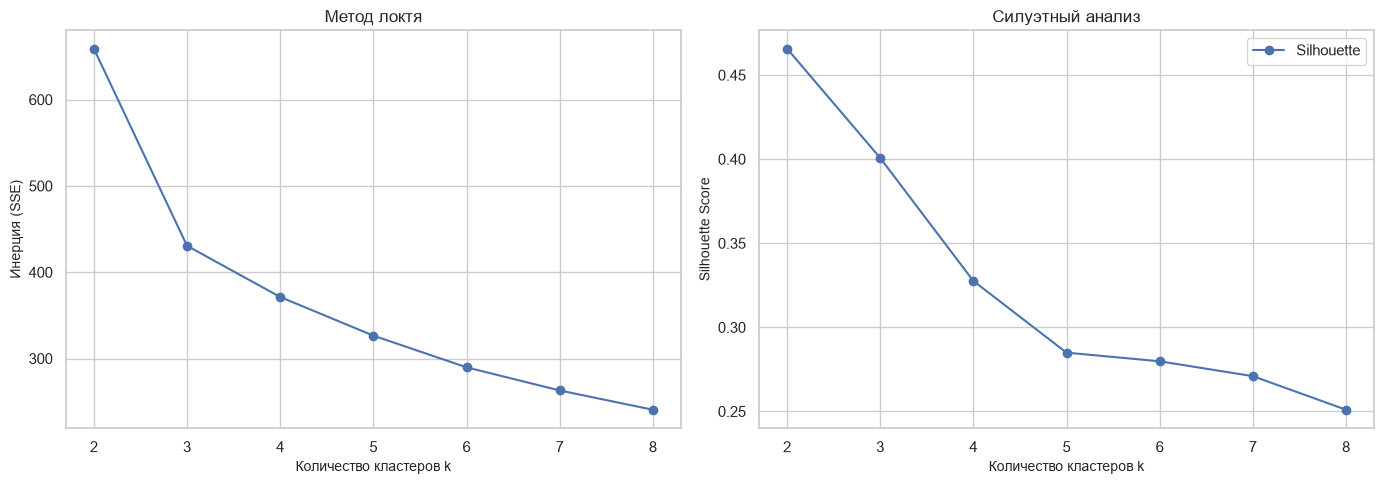

In [84]:
k_values = range(2, 9)
selection_rows = []
kmeans_models = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    kmeans_models[k] = model
    selection_rows.append({
        'k': k,
        'Инерция': model.inertia_,
        'Silhouette': silhouette_score(X_scaled, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, labels),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, labels),
        'ARI к TYPE (только внешняя проверка)': adjusted_rand_score(y_reference, labels)
    })
selection_df = pd.DataFrame(selection_rows)
display(selection_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(selection_df['k'], selection_df['Инерция'], marker='o')
axes[0].set_title('Метод локтя')
axes[0].set_xlabel('Количество кластеров k')
axes[0].set_ylabel('Инерция (SSE)')
axes[0].set_xticks(list(k_values))

axes[1].plot(selection_df['k'], selection_df['Silhouette'], marker='o', label='Silhouette')
axes[1].set_title('Силуэтный анализ')
axes[1].set_xlabel('Количество кластеров k')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_values))
axes[1].legend()
plt.tight_layout()
plt.show()

Инерция (SSE) монотонно убывает с ростом k: 659,17 (k = 2), 430,66 (k = 3), 371,30 (k = 4), 326,51 (k = 5) и далее до 240,64 (k = 8). Наибольшее падение (на 34,7%) происходит при переходе от 2 к 3 кластерам, затем убывание замедляется: на 13,8% (3 → 4), на 12,1% (4 → 5) и не более чем на 11,3% на каждом последующем шаге. Излом кривой («локоть») приходится на k = 3.

Silhouette убывает с ростом k: 0,466 (k = 2), 0,401 (k = 3), 0,328 (k = 4), 0,285 (k = 5), 0,280 (k = 6), 0,271 (k = 7) и 0,251 (k = 8). Максимум формально достигается при k = 2. Значения 0,40-0,47 говорят о слабо выраженной кластерной структуре (по шкале Кауфмана и Руссо значения 0,26-0,50 относятся к слабой структуре), а при k ≥ 4 силуэт опускается ниже 0,33. Индексы Calinski-Harabasz (255,85 при k = 2; 249,78 при k = 3; 203,19 при k = 4) и Davies-Bouldin (0,797; 0,928; 1,063) ведут себя так же: разница между k = 2 и k = 3 невелика (по CH всего 2,4%), а при k ≥ 4 качество заметно ухудшается.

Внутренние критерии указывают на k = 2 или k = 3, значения k ≥ 4 исключаются. Разбиение на два кластера слишком грубое: оно объединяет мелкие и средние зерна, различающиеся по форме. В пользу k = 3 говорят изгиб кривой инерции именно в этой точке, умеренное (а не резкое) падение силуэта и CH при переходе от 2 к 3, три устойчивые ветви на дендрограмме (см. ниже) и три группы на матрице рассеивания. Внешний индекс ARI, который используется только как дополнительная проверка, а не как критерий выбора, также максимален при k = 3 (0,773 против 0,481 при k = 2 и 0,662 при k = 4). Принято k = 3 как компромисс между компактностью кластеров и содержательной интерпретируемостью разбиения.

###  Дендрограмма и выбор числа кластеров для метода Ward


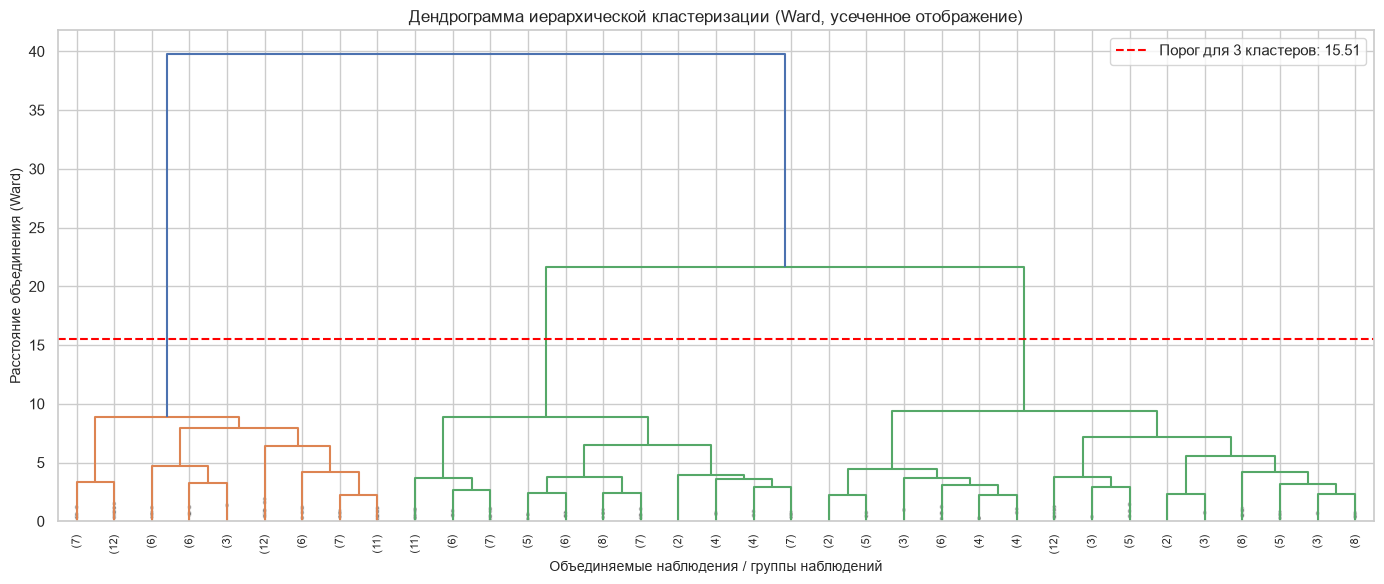

Количество ветвей ниже показанной линии: 3
Для сопоставления с K-means далее фиксируется разбиение Ward на 3 кластера.


In [85]:
linkage_matrix = linkage(X_scaled, method='ward', metric='euclidean')
plt.figure(figsize=(14, 6))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp', p=35,
    show_contracted=True,
    leaf_rotation=90,
    leaf_font_size=8
)

cut_height = (linkage_matrix[-3, 2] + linkage_matrix[-2, 2]) / 2
plt.axhline(y=cut_height, color='red', linestyle='--', label=f'Порог для 3 кластеров: {cut_height:.2f}')
plt.title('Дендрограмма иерархической кластеризации (Ward, усеченное отображение)')
plt.xlabel('Объединяемые наблюдения / группы наблюдений')
plt.ylabel('Расстояние объединения (Ward)')
plt.legend()
plt.tight_layout()
plt.show()
from scipy.cluster.hierarchy import fcluster
ward_cut_labels = fcluster(linkage_matrix, t=cut_height, criterion='distance')
print('Количество ветвей ниже показанной линии:', len(np.unique(ward_cut_labels)))
print('Для сопоставления с K-means далее фиксируется разбиение Ward на 3 кластера.')

### Реализация двух алгоритмов

In [86]:
OPTIMAL_K = 3

kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)

ward = AgglomerativeClustering(n_clusters=OPTIMAL_K, linkage='ward')
labels_ward = ward.fit_predict(X_scaled)

cluster_sizes = pd.DataFrame({
    'K-means': pd.Series(labels_kmeans).value_counts().sort_index(),
    'Ward': pd.Series(labels_ward).value_counts().sort_index()
}).fillna(0).astype(int)
cluster_sizes.index.name = 'Номер кластера (техническая метка)'
print('Размеры кластеров:')
display(cluster_sizes)

Размеры кластеров:


,K-means,Ward
Номер кластера (техническая метка),,
0,72,73
1,67,70
2,71,67


Оба метода дают сбалансированные кластеры: размеры 72, 67 и 71 объект у K-means и 73, 70 и 67 у Ward, то есть примерно по трети выборки, без вырожденных и доминирующих кластеров. Н

### Оценка качества: внутренние и внешние метрики

In [87]:
from math import comb

def pair_agreement_metrics(true_labels, predicted_labels):
    """Внешние метрики на уровне пар объектов: Jaccard и Fowlkes–Mallows."""
    contingency = pd.crosstab(pd.Series(true_labels), pd.Series(predicted_labels)).to_numpy()
    tp = sum(comb(int(n), 2) for n in contingency.ravel() if n >= 2)
    predicted_pairs = sum(comb(int(n), 2) for n in contingency.sum(axis=0) if n >= 2)
    true_pairs = sum(comb(int(n), 2) for n in contingency.sum(axis=1) if n >= 2)
    fp = predicted_pairs - tp
    fn = true_pairs - tp
    jaccard = tp / (tp + fp + fn) if (tp + fp + fn) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    fmi = np.sqrt(precision * recall)
    return jaccard, fmi


def cluster_geometry(X_array, labels):
    """Расстояния внутри кластеров, RMS до центра и матрица расстояний центров."""
    unique_labels = np.sort(np.unique(labels))
    centers = np.vstack([X_array[labels == label].mean(axis=0) for label in unique_labels])
    assigned_centers = np.vstack([centers[np.where(unique_labels == label)[0][0]] for label in labels])
    point_to_center = np.linalg.norm(X_array - assigned_centers, axis=1)
    within_distances = [pdist(X_array[labels == label]) for label in unique_labels]
    within_distances = np.concatenate([d for d in within_distances if len(d) > 0])
    center_distances = cdist(centers, centers)
    upper = center_distances[np.triu_indices_from(center_distances, k=1)]
    return {
        'Среднее попарное расстояние внутри': float(within_distances.mean()),
        'Среднее расстояние до центра': float(point_to_center.mean()),
        'RMS до центра': float(np.sqrt(np.mean(point_to_center ** 2))),
        'Минимальное расстояние между центрами': float(upper.min()),
        'Среднее расстояние между центрами': float(upper.mean()),
        'Матрица расстояний центров': center_distances,
        'Центры': centers
    }


def evaluate_clustering(method_name, X_array, predicted_labels, true_labels):
    geometry = cluster_geometry(X_array, predicted_labels)
    jaccard, fmi = pair_agreement_metrics(true_labels, predicted_labels)
    return {
        'Метод': method_name,
        'Silhouette': silhouette_score(X_array, predicted_labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_array, predicted_labels),
        'Davies-Bouldin': davies_bouldin_score(X_array, predicted_labels),
        'Среднее попарное расстояние внутри': geometry['Среднее попарное расстояние внутри'],
        'Среднее расстояние до центра': geometry['Среднее расстояние до центра'],
        'RMS до центра': geometry['RMS до центра'],
        'Минимальное расстояние между центрами': geometry['Минимальное расстояние между центрами'],
        'Среднее расстояние между центрами': geometry['Среднее расстояние между центрами'],
        'ARI': adjusted_rand_score(true_labels, predicted_labels),
        'AMI': adjusted_mutual_info_score(true_labels, predicted_labels),
        'NMI': normalized_mutual_info_score(true_labels, predicted_labels),
        'Rand': rand_score(true_labels, predicted_labels),
        'Jaccard (парный)': jaccard,
        'Fowlkes-Mallows': fmi
    }

metrics_rows = [
    evaluate_clustering('K-means', X_scaled, labels_kmeans, y_reference),
    evaluate_clustering('Иерархическая (Ward)', X_scaled, labels_ward, y_reference)
]
metrics_df = pd.DataFrame(metrics_rows).set_index('Метод')
print('Сравнительная таблица внутренних и внешних метрик:')
display(metrics_df.round(4))

geometry_kmeans = cluster_geometry(X_scaled, labels_kmeans)
geometry_ward = cluster_geometry(X_scaled, labels_ward)
print('Матрица расстояний между центрами K-means (пространство StandardScaler):')
display(pd.DataFrame(geometry_kmeans['Матрица расстояний центров'], index=range(3), columns=range(3)).round(3))
print('Матрица расстояний между центрами Ward (пространство StandardScaler):')
display(pd.DataFrame(geometry_ward['Матрица расстояний центров'], index=range(3), columns=range(3)).round(3))

Сравнительная таблица внутренних и внешних метрик:


,Silhouette,Calinski-Harabasz,Davies-Bouldin,Среднее попарное расстояние внутри,Среднее расстояние до центра,RMS до центра,Минимальное расстояние между центрами,Среднее расстояние между центрами,ARI,AMI,NMI,Rand,Jaccard (парный),Fowlkes-Mallows
Метод,,,,,,,,,,,,,,
K-means,0.4007,249.7842,0.9279,1.8890,1.3280,1.4320,2.6315,3.7259,0.7733,0.7255,0.7279,0.8997,0.7364,0.8482
Иерархическая (Ward),0.3926,238.3612,0.9445,1.9186,1.3475,1.4558,2.5844,3.7133,0.7970,0.7476,0.7498,0.9102,0.7607,0.8641


Матрица расстояний между центрами K-means (пространство StandardScaler):


,0,1,2
0,0.000,5.153,2.632
1,5.153,0.000,3.393
2,2.632,3.393,0.000


Матрица расстояний между центрами Ward (пространство StandardScaler):


,0,1,2
0,0.000,3.491,2.584
1,3.491,0.000,5.064
2,2.584,5.064,0.000


**Внутренние метрики.** K-means лучше метода Ward по всем трем индексам: Silhouette 0,4007 против 0,3926, Calinski-Harabasz 249,78 против 238,36 (чем выше, тем лучше), Davies-Bouldin 0,9279 против 0,9445 (чем ниже, тем лучше). Различия небольшие (от 2% до 5%), что ожидаемо, так как K-means напрямую минимизирует сумму квадратов расстояний до центров. Silhouette около 0,40 означает слабо выраженную структуру: кластеры различимы, но частично перекрываются. Davies-Bouldin меньше 1: разброс внутри кластеров в среднем меньше расстояния между ними, но запас небольшой.

**Компактность и расстояния между кластерами.** Среднее расстояние до центра равно 1,328 (K-means) и 1,348 (Ward), RMS до центра - 1,432 и 1,456, среднее попарное расстояние внутри кластеров - 1,889 и 1,919: K-means дает немного более компактные кластеры. Минимальное расстояние между центрами составляет 2,632 и 2,584, среднее - 3,726 и 3,713. Минимальное расстояние между центрами менее чем вдвое превышает типичный радиус кластера (RMS около 1,4), поэтому два ближайших кластера почти соприкасаются и перекрываются на границе, что и объясняет умеренные значения силуэта. Матрицы расстояний между центрами в обоих методах дают одну и ту же картину (после сопоставления кластеров по смыслу): мелкие - крупные 5,15 (K-means) и 5,06 (Ward), средние - крупные 3,39 и 3,49, мелкие - средние 2,63 и 2,58. Средний кластер расположен между мелким и крупным и ближе к мелкому.

**Внешние метрики.** По внешним метрикам, наоборот, лучше Ward: ARI 0,7970 против 0,7733, AMI 0,7476 против 0,7255, NMI 0,7498 против 0,7279, Rand 0,9102 против 0,8997, Jaccard 0,7607 против 0,7364, Fowlkes-Mallows 0,8641 против 0,8482. Rand 0,90-0,91 означает, что около 90% пар объектов отнесены так же, как в исходной разметке (с поправкой на случайное совпадение ARI составляет 0,77-0,80, то есть совпадение хорошее, но неполное).

**Итог.** По внутренним метрикам немного лучше K-means, по внешним - Ward, но все различия малы (0,01-0,03 по внешним метрикам). Оба метода восстанавливают исходные разновидности примерно с одинаковым качеством (ARI около 0,8), поэтому ни один из них не имеет явного преимущества по метрикам.

### Центры кластеров и интерпретация групп

In [88]:
def make_cluster_profiles(method_name, labels):
    frame = X.copy()
    frame['Кластер'] = labels
    profiles = frame.groupby('Кластер')[FEATURES].mean()
    sizes = frame.groupby('Кластер').size().rename('Количество объектов')
    profiles = profiles.join(sizes)
    cross = pd.crosstab(pd.Series(labels, name='Кластер'), y_reference.map(CLASS_NAMES))
    dominant_class = cross.idxmax(axis=1).rename('Преобладающая TYPE-группа')
    dominant_share = (cross.max(axis=1) / cross.sum(axis=1)).rename('Доля преобладающей группы')
    profiles = profiles.join(dominant_class).join(dominant_share)
    profiles.insert(0, 'Метод', method_name)
    return profiles.reset_index()

profiles_kmeans = make_cluster_profiles('K-means', labels_kmeans)
profiles_ward = make_cluster_profiles('Ward', labels_ward)
cluster_profiles = pd.concat([profiles_kmeans, profiles_ward], ignore_index=True)
print('Средние значения признаков внутри кластеров (исходные единицы):')
display(cluster_profiles.round(4))

centers_scaled = []
for method_name, labels in [('K-means', labels_kmeans), ('Ward', labels_ward)]:
    temp = X_scaled_df.copy()
    temp['Кластер'] = labels
    means = temp.groupby('Кластер')[FEATURES].mean().reset_index()
    means.insert(0, 'Метод', method_name)
    centers_scaled.append(means)
centers_scaled_df = pd.concat(centers_scaled, ignore_index=True)
print('Центры кластеров в стандартизованных единицах (z-оценки):')
display(centers_scaled_df.round(3))

Средние значения признаков внутри кластеров (исходные единицы):


,Кластер,Метод,AREA,PERIMETER,COMPACTNESS,LENGTH,WIDTH,ASSYMMETRY_COEFFICIENT,GROOVE_LENGTH,Количество объектов,Преобладающая TYPE-группа,Доля преобладающей группы
0,0,K-means,11.8569,13.2478,0.8483,5.2318,2.8495,4.7424,5.1017,72,Canadian,0.9167
1,1,K-means,18.4954,16.2034,0.8842,6.1757,3.6975,3.6324,6.0417,67,Rosa,0.9701
2,2,K-means,14.4379,14.3377,0.8816,5.5146,3.2592,2.7073,5.1208,71,Kama,0.8732
3,0,Ward,14.1990,14.2336,0.8792,5.4782,3.2265,2.6122,5.0862,73,Kama,0.8767
4,1,Ward,18.3714,16.1454,0.8844,6.1582,3.6846,3.6392,6.0174,70,Rosa,0.9429
5,2,Ward,11.8724,13.2570,0.8481,5.2389,2.8485,4.9494,5.1222,67,Canadian,0.9701


Центры кластеров в стандартизованных единицах (z-оценки):


,Метод,Кластер,AREA,PERIMETER,COMPACTNESS,LENGTH,WIDTH,ASSYMMETRY_COEFFICIENT,GROOVE_LENGTH
0,K-means,0,-1.030,-1.007,-0.965,-0.898,-1.086,0.695,-0.625
1,K-means,1,1.257,1.262,0.560,1.238,1.165,-0.045,1.292
2,K-means,2,-0.141,-0.170,0.450,-0.258,0.002,-0.662,-0.586
3,Ward,0,-0.223,-0.250,0.348,-0.340,-0.085,-0.725,-0.657
4,Ward,1,1.214,1.217,0.569,1.198,1.131,-0.041,1.243
5,Ward,2,-1.025,-1.000,-0.973,-0.881,-1.088,0.833,-0.583


По средним значениям признаков прослеживаются три характерных профиля зерен:

1. Крупные зерна. У этой группы наибольшие средние площадь и периметр (около 18,4–18,5 и 16,1–16,2), длина (около 6,16), ширина (около 3,68–3,70) и длина бороздки (около 6,02–6,04). В обеих моделях эта группа преимущественно соответствует `TYPE=2` - Rosa. Это наиболее крупные зерна по основным линейным характеристикам.
2. Зерна среднего размера. Средняя площадь составляет примерно 14,2–14,4, периметр - 14,2–14,3, ширина - около 3,23–3,26. Коэффициент асимметрии у этой группы ниже (примерно 2,6–2,7), чем у группы мелких зерен. Она преимущественно соответствует `TYPE=1` - Kama.
3. Мелкие зерна с более высокой асимметрией. Средняя площадь составляет около 11,86–11,87, периметр - около 13,25, длина - примерно 5,23, ширина - около 2,85. Средний коэффициент асимметрии выше (около 4,74–4,95). Эта группа преимущественно соответствует `TYPE=3` - Canadian.

Порядок кластеров в K-means и Ward различается, поэтому сравнивать нужно профиль и состав группы, а не технический номер. В обоих методах выделяется одна и та же содержательная структура: крупные зерна, зерна среднего размера и более мелкие зерна с повышенной асимметрией. Ошибки внешнего сопоставления возникают в основном у пограничных наблюдений, чьи характеристики близки сразу к двум профилям.

### Влияние параметра k на качество K-means

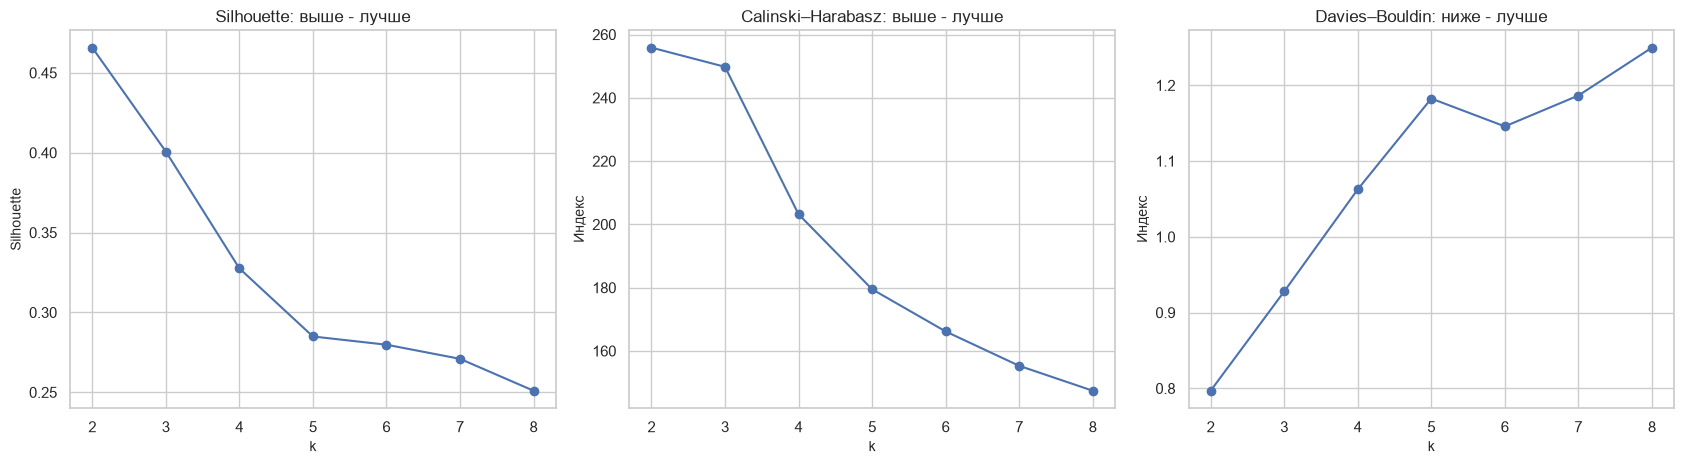

Сводка по значениям k:


,k,Инерция,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI к TYPE (только внешняя проверка)
0,2,659.1718,0.4658,255.8548,0.7969,0.4805
1,3,430.6590,0.4007,249.7842,0.9279,0.7733
2,4,371.3017,0.3276,203.1877,1.0626,0.6624
3,5,326.5137,0.2849,179.4830,1.1825,0.5211
4,6,289.8040,0.2798,166.1536,1.1457,0.4719
5,7,262.9736,0.2709,155.2921,1.1864,0.3805
6,8,240.6426,0.2510,147.4209,1.2497,0.3192


In [89]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].plot(selection_df['k'], selection_df['Silhouette'], marker='o')
axes[0].set_title('Silhouette: выше - лучше')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Silhouette')
axes[0].set_xticks(list(k_values))

axes[1].plot(selection_df['k'], selection_df['Calinski-Harabasz'], marker='o')
axes[1].set_title('Calinski–Harabasz: выше - лучше')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Индекс')
axes[1].set_xticks(list(k_values))

axes[2].plot(selection_df['k'], selection_df['Davies-Bouldin'], marker='o')
axes[2].set_title('Davies–Bouldin: ниже - лучше')
axes[2].set_xlabel('k')
axes[2].set_ylabel('Индекс')
axes[2].set_xticks(list(k_values))
plt.tight_layout()
plt.show()

print('Сводка по значениям k:')
display(selection_df[['k', 'Инерция', 'Silhouette', 'Calinski-Harabasz', 'Davies-Bouldin', 'ARI к TYPE (только внешняя проверка)']].round(4))

- **Silhouette** убывает с ростом k (0,466 → 0,401 → 0,328 → ... → 0,251), **Calinski-Harabasz** убывает с 255,85 при k = 2 до 147,42 при k = 8, **Davies-Bouldin** в целом растет (0,797 при k = 2 и 1,250 при k = 8; небольшое локальное улучшение при k = 6, 1,146 против 1,183 при k = 5, не меняет общей тенденции). Это означает, что при дальнейшем делении облако точек без разрывов дробится внутри компактных групп, и кластеры становятся менее разделенными.
- **Инерция** по построению убывает при любом увеличении k, поэтому по ней одной оптимальное k выбрать нельзя; информативен только излом на k = 3.
- **ARI относительно TYPE** максимален при k = 3 (0,773) и падает как при уменьшении k (0,481 при k = 2: две исходные разновидности объединяются), так и при увеличении (0,662 при k = 4, 0,521 при k = 5, 0,319 при k = 8: исходные группы дробятся на части).

Таким образом, k = 3 - это точка, где качество внутренних индексов еще остается приемлемым (потеря силуэта относительно k = 2 составляет 0,065, а следующий шаг до k = 4 стоит дороже - 0,073), а разбиение при этом лучше всего согласуется с реальными группами зерен.

## Визуализация результатов

Доля объясненной дисперсии PC1: 0.7187 (71.9%)
Доля объясненной дисперсии PC2: 0.1711 (17.1%)
Суммарно двумя компонентами: 0.8898 (89.0%)


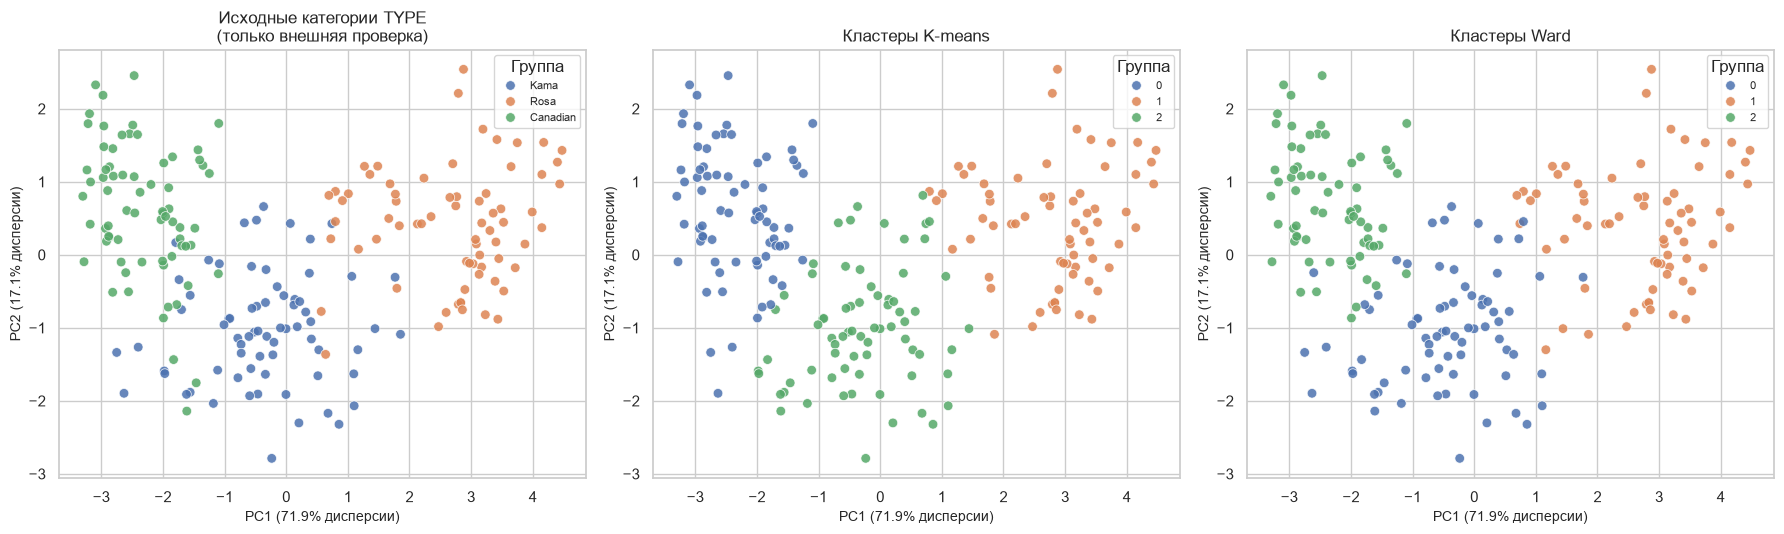

In [90]:
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)
explained = pca_2d.explained_variance_ratio_
print(f'Доля объясненной дисперсии PC1: {explained[0]:.4f} ({explained[0]:.1%})')
print(f'Доля объясненной дисперсии PC2: {explained[1]:.4f} ({explained[1]:.1%})')
print(f'Суммарно двумя компонентами: {explained.sum():.4f} ({explained.sum():.1%})')

pca_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'Исходная разновидность': y_reference.map(CLASS_NAMES).values,
    'K-means': labels_kmeans,
    'Ward': labels_ward
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Исходная разновидность',
                palette='deep', s=48, alpha=0.85, ax=axes[0])
axes[0].set_title('Исходные категории TYPE\n(только внешняя проверка)')
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='K-means',
                palette='deep', s=48, alpha=0.85, ax=axes[1])
axes[1].set_title('Кластеры K-means')
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Ward',
                palette='deep', s=48, alpha=0.85, ax=axes[2])
axes[2].set_title('Кластеры Ward')
for ax in axes:
    ax.set_xlabel(f'PC1 ({explained[0]:.1%} дисперсии)')
    ax.set_ylabel(f'PC2 ({explained[1]:.1%} дисперсии)')
    ax.legend(title='Группа', fontsize=8)
plt.tight_layout()
plt.show()

Первые две главные компоненты сохраняют примерно **88,98%** общей дисперсии: PC1 - около 71,87%, PC2 - около 17,11%. Поэтому двумерный график достаточно хорошо отражает общую геометрию исходного семимерного пространства, хотя часть информации все равно теряется.

На диаграммах видны три основные области. Крупные зерна образуют хорошо выраженную отдельную группу; группа зерен среднего размера располагается отдельно от нее; более мелкие зерна имеют собственную область, хотя на границах наблюдается частичное сближение. Результаты K-means и Ward визуально похожи, что соответствует высокому ARI между их разбиениями. При этом некоторые точки около границ групп распределяются по-разному - это объясняет, почему внешние показатели не равны единице.

График исходных TYPE приведен исключительно для проверки результата после обучения. Он не использовался при масштабировании, PCA-моделировании кластеров, подборе начальных центров или обучении алгоритмов.

### Сравнение методов и устойчивость кластеров

In [ ]:
for method_name, labels in [('K-means', labels_kmeans), ('Ward', labels_ward)]:
    contingency = pd.crosstab(
        pd.Series(y_reference.map(CLASS_NAMES), name='Исходная разновидность'),
        pd.Series(labels, name='Кластер')
    )
    print(f'Таблица сопряженности: {method_name}')
    display(contingency)
    row_ind, col_ind = linear_sum_assignment(-contingency.to_numpy())
    matched = int(contingency.to_numpy()[row_ind, col_ind].sum())
    print(f'Наилучшее сопоставление: {matched} из {len(df)} объектов ({matched / len(df):.1%})')

print('Согласие двух алгоритмов между собой, измеренное ARI (1 — одинаковое разбиение с точностью до перестановки меток):')
print(f'ARI(K-means, Ward) = {adjusted_rand_score(labels_kmeans, labels_ward):.4f}')

Таблица сопряженности: K-means


Кластер,0,1,2
Исходная разновидность,,,
Canadian,66,0,4
Kama,6,2,62
Rosa,0,65,5


Наилучшее сопоставление: 193 из 210 объектов (91.9%)
Таблица сопряженности: Ward


Кластер,0,1,2
Исходная разновидность,,,
Canadian,5,0,65
Kama,64,4,2
Rosa,4,66,0


Наилучшее сопоставление: 195 из 210 объектов (92.9%)
Согласие двух алгоритмов между собой, измеренное ARI (1 — одинаковое разбиение с точностью до перестановки меток):
ARI(K-means, Ward) = 0.8359


У K-means основная часть наблюдений исходного типа Kama попадает в один кластер (62 из 70), типа Rosa — в другой (65 из 70), типа Canadian — в третий (66 из 70). У Ward соответствующие основные количества составляют 64, 66 и 65 объектов. При оптимальном сопоставлении кластеров исходным разновидностям правильно согласуются 193 из 210 наблюдений для K-means (91,9%) и 195 из 210 для Ward (92,9%). Это описательная доля после оптимального сопоставления меток, а не точность обученного классификатора.

ARI между самими разбиениями K-means и Ward равен примерно **0,8359**. Следовательно, два разных алгоритма в значительной степени находят одну и ту же структуру данных, хотя отдельные пограничные наблюдения распределяются по-разному. Это подтверждает устойчивость общей трехгрупповой структуры.

тут еще доделать

## Заключение

В ходе лабораторной работы был выполнен анализ датасета seed.csv, содержащего 210 наблюдений и семь числовых признаков зерен пшеницы. Исходная разметка TYPE включает три сбалансированные группы — Kama, Rosa и Canadian — по 70 объектов в каждой. Пропусков и полных дубликатов не обнаружено. По правилу 1,5 × IQR выявлено лишь пять слабых потенциальных выбросов; они были оставлены в выборке, поскольку не являются грубыми ошибками и отражают естественную изменчивость формы зерен.

Признаки имеют разные масштабы: например, размах AREA составляет 10,59, а COMPACTNESS — только 0,11. Поэтому перед кластеризацией была выполнена стандартизация StandardScaler. Без неё признаки с большим числовым размахом доминировали бы в евклидовом расстоянии. Матрица диаграмм рассеивания показала, что размерные признаки связаны почти линейно, а данные образуют несколько перекрывающихся компактных групп. Для кластеризации были выбраны K-means и иерархическая кластеризация методом Ward: оба метода ориентированы на компактные, выпуклые кластеры и подходят для наблюдаемой структуры.

Оптимальное число кластеров k = 3 выбрано по совокупности критериев. На кривой инерции излом приходится на переход от 2 к 3 кластерам; Silhouette, Calinski–Harabasz и Davies–Bouldin также указывают на k = 2 или k = 3, тогда как k ≥ 4 заметно ухудшает внутренние метрики. Дендрограмма Ward подтверждает наличие трёх основных ветвей. Внешний ARI относительно TYPE максимален именно при k = 3 (0,773), что служит дополнительной проверкой, но не критерием обучения.

Оба метода дали сбалансированные кластеры: у K-means — 72, 67 и 71 объект, у Ward — 73, 70 и 67 объектов. По внутренним метрикам K-means немного лучше: Silhouette 0,4007 против 0,3926, Calinski–Harabasz 249,78 против 238,36, Davies–Bouldin 0,9279 против 0,9445. K-means также даёт чуть более компактные кластеры: среднее расстояние до центра 1,328 против 1,348, RMS до центра 1,432 против 1,456. По внешним метрикам, наоборот, немного лучше Ward: ARI 0,7970 против 0,7733, AMI 0,7476 против 0,7255, NMI 0,7498 против 0,7279, Rand 0,9102 против 0,8997, Jaccard 0,7607 против 0,7364, Fowlkes–Mallows 0,8641 против 0,8482. При оптимальном сопоставлении кластеров исходным разновидностям правильно согласуются 193 из 210 объектов для K-means (91,9%) и 195 из 210 для Ward (92,9%). Различия между методами малы, поэтому ни один из них не имеет решающего преимущества по метрикам.

Содержательно выделены три устойчивых профиля зерен. Крупные зерна имеют наибольшие площадь, периметр, длину, ширину и длину бороздки и преимущественно соответствуют Rosa. Зерна среднего размера характеризуются промежуточными линейными размерами и более низким коэффициентом асимметрии; они в основном соответствуют Kama. Мелкие зерна имеют наименьшие площадь и ширину, но повышенный коэффициент асимметрии; эта группа преимущественно соответствует Canadian. Наиболее устойчивы кластеры крупных и мелких зерен; кластер средних зерен менее устойчив, поскольку занимает промежуточное положение и перекрывается с соседними группами.

Устойчивость структуры подтверждается повторными запусками K-means, bootstrap-проверкой и высоким согласием двух алгоритмов: ARI(K-means, Ward) ≈ 0,8359. Это означает, что три группы воспроизводятся разными методами и не являются артефактом одной инициализации. Основные расхождения возникают на границах кластеров, где объекты по своим признакам близки сразу к двум профилям.

Таким образом, цель работы достигнута: освоены методы кластеризации, выполнена стандартизация признаков, обоснован выбор k = 3, рассчитаны внутренние и внешние метрики, проведена содержательная интерпретация кластеров и проверена их устойчивость. Для данного датасета K-means можно рекомендовать как более быстрый и лучше оптимизирующий компактность метод, а Ward — как детерминированный метод, который немного лучше согласуется с исходными разновидностями и удобен для визуального анализа структуры с помощью дендрограммы.

## Список источников

## Приложение
Исходный код: https://github.com/violllin/lab3_clustering/blob/main/lab3.ipynb